# 05 · Clustering no supervisado de perfiles territoriales (Paso 09)

**Pregunta:** ¿qué perfiles de siniestralidad distinguen a los barrios de CABA?

**Skills aplicadas:** `clustering-research`, `colab-ml-validation` (sección de clustering), `jupyter-notebooks` y `ml-scientific-reviewer`. **Informe y dictamen:** [docs/clustering_report.md](../docs/clustering_report.md).

| Elemento | Definición |
|---|---|
| Unidades | 48 barrios |
| Ventana | Desarrollo 2019–2024 **sin meses anómalos** (55 meses). **2025 no se usa**: no se incorporan resultados futuros |
| Atributos | **Perfil relativo**: horario, fin de semana, estacionalidad, modo de la víctima y tipo de vía del hecho (`src/profiles.py`). **Volumen** (nivel y densidad) solo en la variante V |
| Excluidos de los atributos | Gravedad (KSI, E9), infraestructura vigente (D11) y SD (se describe aparte) |
| Métodos | K-Means y jerárquico Ward con el mismo preprocesamiento; jerárquico *average* y HDBSCAN como alternativas de forma o densidad |
| Evaluación | *Silhouette*, Calinski-Harabasz, Davies-Bouldin; estabilidad por *bootstrap* de barrios (ARI), por semilla, por período y por familia de atributos; sensibilidad al escalado; tamaños; interpretabilidad en unidades originales |

**Reglas fijadas antes de ver los resultados.**
1. **Cribado de atributos.** Se conserva un atributo si la varianza observada entre barrios es al menos el doble de la varianza esperada solo por muestreo (binomial, con el n de cada barrio). Es decir, cociente señal/ruido ≥ 2.
2. **Selección.** Se considera K-Means y Ward sobre el conjunto relativo cribado, con escalado estándar y k entre 2 y 8. Son elegibles las soluciones con **ARI medio por *bootstrap* ≥ 0,60** y **todos los grupos con al menos 3 barrios**. Entre ellas gana la de mayor *silhouette*; si la diferencia es menor que 0,01, gana la de menor k. Si ninguna es elegible, se elige la de mayor ARI y se declara la estructura débil.
3. **Umbral de interpretación.** Con *silhouette* < 0,25, la separación se considera débil (Kaufman y Rousseeuw).

### Guía para el lector

**La pregunta, en una frase.** Más allá de cuántos siniestros tiene cada barrio, ¿hay grupos de barrios con siniestros **de distinto tipo**: con otros usuarios involucrados, en otras vías u otros horarios?

**Por qué importa.** El notebook 04 dice *dónde* priorizar. Este orienta *qué tipo* de prevención: no es lo mismo actuar sobre vías rápidas que sobre peatones en avenidas.

**Cómo se procede.**
1. Se describe cada barrio con proporciones de sus hechos de 2019–2024, sin meses anómalos y sin datos de 2025 (§0).
2. Se descartan los atributos cuya variación entre barrios podría deberse al azar (§1).
3. Se comparan varios métodos de agrupamiento y cantidades de grupos (§2) y se elige con una regla fijada **antes** de ver los resultados (§3).
4. Se comprueba la solidez de la solución (§4) y se describen los grupos con números interpretables (§5 y §5b).

**Resultado principal.** Hay **dos perfiles claros**:
- **Borde** (9 barrios junto a la General Paz y las autopistas): más hechos en vías rápidas, con autos y motos.
- **Interior** (39 barrios): hechos en avenidas y calles, con más peatones, ciclistas y transporte público.

La separación es razonable (*silhouette* 0,33) y resiste cambios de escalado, de período y de atributos, salvo quitar el tipo de vía. Un segundo nivel divide el interior en **central-denso** (17) y **residencial** (22), pero esa división es débil (*silhouette* 0,195) y solo orientativa.

**Qué no dicen los perfiles.** No miden peligrosidad ni volumen: ambos grupos tienen cantidades de hechos y proporciones de gravedad parecidas. Tampoco explican causas.

### Glosario y atributos de este notebook

| Término | Significado |
|---|---|
| ***Clustering*** | Agrupar unidades parecidas sin una respuesta correcta conocida de antemano. |
| **K-Means; Ward; *average*; HDBSCAN** | Métodos de agrupamiento: por centros, jerárquico que minimiza la variación dentro de cada grupo, jerárquico por distancia promedio, y por densidad (este último puede dejar unidades como «ruido»). |
| **k** | Cantidad de grupos. |
| **Escalado (estándar, robusto, min-max)** | Pone los atributos en escalas comparables antes de medir distancias. |
| ***Silhouette*** | Qué tan separados están los grupos, entre −1 y 1. Por debajo de 0,25 la estructura se considera débil. |
| **Calinski-Harabasz; Davies-Bouldin** | Otras medidas de separación: más alto es mejor en la primera y más bajo es mejor en la segunda. |
| **ARI; *bootstrap*** | Coincidencia entre dos particiones (1 = idénticas); se calcula repitiendo el agrupamiento con barrios remuestreados para medir la estabilidad. |
| **Cociente señal/ruido** | Varianza observada entre barrios dividida por la esperable solo por azar de muestreo. Se conservan los atributos con 2 o más. |
| **η²** | Proporción de la variación de una variable (por ejemplo, el volumen) explicada por los grupos. |
| **R; R+V** | Conjunto de atributos relativos; el mismo conjunto más volumen (nivel y densidad). |
| **Anidamiento** | La solución con k = 3 conserva el grupo de borde de k = 2 y solo divide el interior. |

**Atributos que entran al agrupamiento** (proporciones de los hechos de cada barrio; definidas en `src/profiles.py`):

| Atributo | Qué mide | Denominador |
|---|---|---|
| `pct_moto`, `pct_peaton`, `pct_bicicleta`, `pct_auto`, `pct_transporte_publico` | Modo de la víctima | Hechos con modo informado (sin SD) |
| `pct_avenida`, `pct_autopista_gralpaz` | Tipo de vía registrado en el hecho | Hechos de 2020 en adelante con vía informada |
| `pct_fin_de_semana`, `pct_madrugada_0_5` | Momento del hecho | Hechos con hora informada |

Las franjas diurnas, la estación del año y «otros modos» se descartan en la §1 porque su variación entre barrios es compatible con el azar. La gravedad (KSI), la infraestructura actual y el volumen no entran en la solución principal.

## 0. Datos y atributos

> **Qué hace la celda siguiente.** Carga los hechos limpios y calcula, para cada barrio, las proporciones de hechos por horario, día, estación, modo y tipo de vía en los 55 meses de desarrollo sin anomalías. **Qué mirar en la salida:** el barrio con menos hechos (Coghlan) tiene 177, suficientes para calcular proporciones.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src import profiles as P
warnings.filterwarnings("ignore")
FIG, TAB = ROOT / "reports" / "figures" / "05_clustering", ROOT / "reports" / "tables" / "05_clustering"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10})
SEED = 20261110; M = {}
h = pd.read_csv(ROOT / "data" / "processed" / "hechos_clean.csv", dtype={"mes": str}, low_memory=False)
panel = pd.read_csv(ROOT / "data" / "processed" / "panel_barrio_mes.csv", dtype={"mes": str})
area = panel.groupby("barrio")["area_km2"].first()
MONTHS = P.default_months()
A = P.build_attributes(h, area, MONTHS)
A.round(4).to_csv(TAB / "atributos_barrio.csv")
M["ventana"] = {"meses": len(MONTHS), "desde": MONTHS[0], "hasta": MONTHS[-1], "hechos_min_barrio": int(A["hechos"].min()), "barrio_min": A["hechos"].idxmin()}
print(M["ventana"]); A[P.ATTR_RELATIVO].describe().T[["mean", "std", "min", "max"]].round(3)

{'meses': 55, 'desde': '2019-01', 'hasta': '2024-12', 'hechos_min_barrio': 177, 'barrio_min': 'Coghlan'}


,mean,std,min,max
pct_madrugada_0_5,0.073,0.017,0.034,0.119
pct_manana_6_11,0.249,0.025,0.197,0.298
pct_tarde_12_17,0.405,0.027,0.331,0.468
pct_noche_18_23,0.272,0.026,0.220,0.362
pct_fin_de_semana,0.206,0.026,0.166,0.281
pct_trim1,0.226,0.022,0.180,0.266
pct_trim2,0.244,0.020,0.209,0.313
pct_trim3,0.277,0.020,0.230,0.335
pct_trim4,0.252,0.025,0.189,0.343
pct_moto,0.450,0.054,0.342,0.583


## 1. Cribado de atributos: señal frente a ruido de muestreo

Para cada proporción se calcula la varianza esperada solo por muestreo, Σ p̄(1 − p̄)/nᵢ / 48, con el denominador nᵢ de cada barrio, y se la compara con la varianza observada entre barrios. Un cociente cercano a 1 indica que las diferencias entre barrios son compatibles con el azar.

> **Qué hace la celda siguiente.** Compara, para cada atributo, la variación real entre barrios con la que se esperaría solo por azar de muestreo, y descarta los que no la superan al menos dos veces.

In [2]:
hh = h[h["mes"].isin(MONTHS) & h["barrio"].notna()]
n_hora = hh.dropna(subset=["hora_entera"]).groupby("barrio").size()
n_modo = hh[hh["modo_victima"] != "SD"].groupby("barrio").size()
n_via = hh[(hh["anio"] >= 2020) & (hh["tipo_de_via"] != "SD")].groupby("barrio").size()
den = {**{c: n_hora for c in P.ATTR_HORARIO[:-1]}, "pct_fin_de_semana": A["hechos"], **{c: A["hechos"] for c in P.ATTR_ESTACION},
       **{c: n_modo for c in P.ATTR_MODO}, **{c: n_via for c in P.ATTR_VIA}}
rows = []
for c in P.ATTR_RELATIVO:
    pbar = A[c].mean(); exp_var = float((pbar * (1 - pbar) / den[c].reindex(A.index)).mean())
    rows.append({"atributo": c, "var_observada": A[c].var(), "var_esperada_muestreo": exp_var, "senal_ruido": A[c].var() / exp_var})
sn = pd.DataFrame(rows).set_index("atributo").round(6); sn["conservado"] = sn["senal_ruido"] >= 2
ATTR_R = sn.index[sn["conservado"]].tolist(); ATTR_RV = ATTR_R + P.ATTR_VOLUMEN
sn.to_csv(TAB / "cribado_senal_ruido.csv"); M["cribado"] = {"conservados": ATTR_R, "descartados": sn.index[~sn["conservado"]].tolist()}
print("Conservados:", ATTR_R); print("Descartados:", M["cribado"]["descartados"]); sn.sort_values("senal_ruido", ascending=False).round(2)

Conservados: ['pct_madrugada_0_5', 'pct_fin_de_semana', 'pct_moto', 'pct_peaton', 'pct_bicicleta', 'pct_auto', 'pct_transporte_publico', 'pct_avenida', 'pct_autopista_gralpaz']
Descartados: ['pct_manana_6_11', 'pct_tarde_12_17', 'pct_noche_18_23', 'pct_trim1', 'pct_trim2', 'pct_trim3', 'pct_trim4', 'pct_otros_modos']


,var_observada,var_esperada_muestreo,senal_ruido,conservado
atributo,,,,
pct_autopista_gralpaz,0.02,0.0,132.49,True
pct_avenida,0.02,0.0,43.35,True
pct_bicicleta,0.00,0.0,7.25,True
pct_auto,0.00,0.0,7.14,True
pct_peaton,0.00,0.0,6.84,True
pct_moto,0.00,0.0,5.81,True
pct_transporte_publico,0.00,0.0,3.45,True
pct_fin_de_semana,0.00,0.0,2.48,True
pct_madrugada_0_5,0.00,0.0,2.47,True


**Lectura (1).**
- **Conservados (cociente ≥ 2).** Los **9 atributos** de modo de la víctima (moto, peatón, bicicleta, auto, transporte público), tipo de vía (avenida; autopista o General Paz), fin de semana y madrugada.
- **Descartados.** Las franjas diurnas, la **estacionalidad trimestral** y "otros modos". Su variación entre barrios es compatible con el ruido de muestreo (cociente entre 1,1 y 1,9): con barrios de 177 a 3.461 hechos, no hay evidencia de que la estacionalidad difiera entre barrios. Los perfiles se apoyan, entonces, en **composición modal y tipo de vía**.
- **Señal más fuerte.** El tipo de vía (cocientes de 43 y 132), seguido por la composición modal (entre 3,5 y 7,3).

## 2. Comparación de métodos, k y escalados

> **Qué hace la celda siguiente.** Prueba K-Means, Ward y *average* con k de 2 a 8, con y sin volumen y con tres escalados, y calcula la separación (*silhouette* y otras medidas) y la estabilidad (ARI por *bootstrap*) de cada solución.

In [3]:
SCALERS = {"standard": StandardScaler, "robust": RobustScaler, "minmax": MinMaxScaler}
def Z_of(cols, scaler="standard"):
    return SCALERS[scaler]().fit_transform(A[cols].to_numpy(float))
def fitter(method, k):
    if method == "kmeans": return lambda Z: KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)
    if method == "ward": return lambda Z: AgglomerativeClustering(k, linkage="ward").fit_predict(Z)
    if method == "average": return lambda Z: AgglomerativeClustering(k, linkage="average").fit_predict(Z)
rows, SOL = [], {}
for set_name, cols in [("R", ATTR_R), ("R+V", ATTR_RV)]:
    for scaler in SCALERS:
        Z = Z_of(cols, scaler)
        for method in ["kmeans", "ward", "average"]:
            for k in range(2, 9):
                fp = fitter(method, k); lab = fp(Z); SOL[(set_name, scaler, method, k)] = lab
                ari = P.bootstrap_ari(Z, fp, lab, reps=200, seed=SEED) if scaler == "standard" else np.array([np.nan])
                rows.append({"conjunto": set_name, "escalado": scaler, "metodo": method, "k": k,
                             "silhouette": silhouette_score(Z, lab), "calinski_harabasz": calinski_harabasz_score(Z, lab),
                             "davies_bouldin": davies_bouldin_score(Z, lab), "ari_bootstrap_media": float(np.nanmean(ari)),
                             "ari_bootstrap_p10": float(np.nanquantile(ari, .1)) if scaler == "standard" else np.nan,
                             "tamano_min": int(np.bincount(lab).min()), "tamanos": "/".join(map(str, sorted(np.bincount(lab), reverse=True)))})
res = pd.DataFrame(rows); res.to_csv(TAB / "comparacion_metodos.csv", index=False)
# HDBSCAN (densidad), sobre el conjunto relativo estandarizado
hd = []
for mcs in [3, 4, 5, 6]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(Z_of(ATTR_R)); nn = lab >= 0
    hd.append({"min_cluster_size": mcs, "grupos": int(lab.max() + 1), "pct_ruido": round(float((~nn).mean() * 100), 1),
               "silhouette_sin_ruido": float(silhouette_score(Z_of(ATTR_R)[nn], lab[nn])) if lab.max() >= 1 and nn.sum() > lab.max() + 1 else np.nan})
hd = pd.DataFrame(hd); hd.to_csv(TAB / "hdbscan.csv", index=False); M["hdbscan"] = hd.to_dict(orient="records")
std = res[res["escalado"] == "standard"]
display(std.pivot_table(index=["conjunto", "metodo"], columns="k", values="silhouette").round(3))
display(std.pivot_table(index=["conjunto", "metodo"], columns="k", values="ari_bootstrap_media").round(2)); hd

k                     2      3      4      5      6      7      8
conjunto metodo                                                  
R        average  0.444  0.293  0.229  0.195  0.173  0.148  0.137
         kmeans   0.330  0.195  0.183  0.183  0.184  0.187  0.212
         ward     0.330  0.184  0.147  0.156  0.160  0.162  0.192
R+V      average  0.420  0.225  0.141  0.186  0.165  0.138  0.128
         kmeans   0.273  0.190  0.180  0.181  0.185  0.179  0.177
         ward     0.278  0.206  0.187  0.184  0.192  0.160  0.164

k                    2     3     4     5     6     7     8
conjunto metodo                                           
R        average  0.57  0.64  0.67  0.64  0.71  0.64  0.62
         kmeans   0.86  0.70  0.55  0.52  0.49  0.50  0.50
         ward     0.82  0.52  0.45  0.45  0.47  0.50  0.51
R+V      average  0.59  0.40  0.36  0.53  0.59  0.55  0.50
         kmeans   0.72  0.73  0.62  0.64  0.59  0.56  0.55
         ward     0.67  0.53  0.55  0.55  0.57  0.51  0.51

,min_cluster_size,grupos,pct_ruido,silhouette_sin_ruido
0,3,2,62.5,0.262703
1,4,0,100.0,NaN
2,5,0,100.0,NaN
3,6,0,100.0,NaN


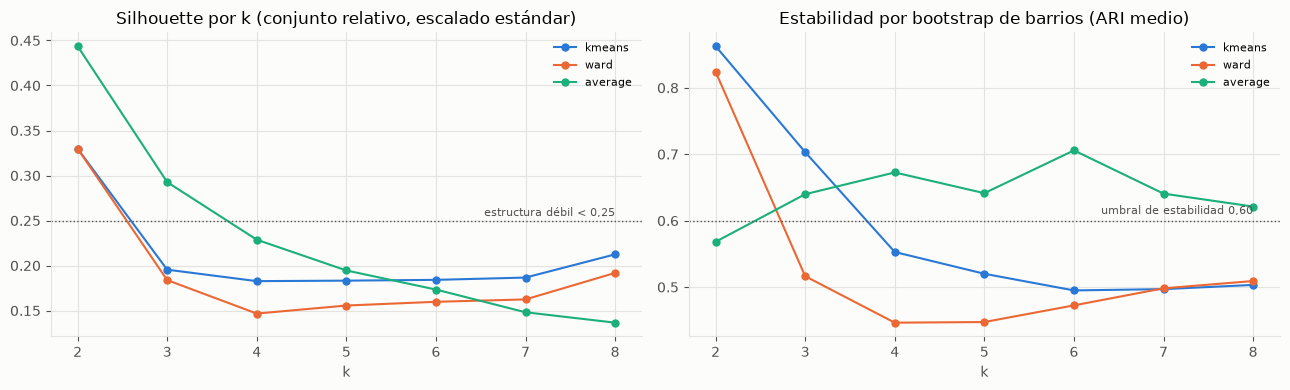

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (meth, col) in enumerate([("kmeans", CAT[0]), ("ward", CAT[1]), ("average", CAT[2])]):
    d = std[(std["conjunto"] == "R") & (std["metodo"] == meth)]
    axes[0].plot(d["k"], d["silhouette"], marker="o", ms=5, color=col, label=meth)
    axes[1].plot(d["k"], d["ari_bootstrap_media"], marker="o", ms=5, color=col, label=meth)
axes[0].axhline(.25, color=INK2, ls=":", lw=1); axes[0].text(8, .255, "estructura débil < 0,25", ha="right", fontsize=8, color=INK2)
axes[1].axhline(.6, color=INK2, ls=":", lw=1); axes[1].text(8, .61, "umbral de estabilidad 0,60", ha="right", fontsize=8, color=INK2)
axes[0].set_title("Silhouette por k (conjunto relativo, escalado estándar)"); axes[1].set_title("Estabilidad por bootstrap de barrios (ARI medio)")
for ax in axes: ax.set_xlabel("k"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "silhouette_estabilidad.png", dpi=150); plt.show()

## 3. Selección con la regla fijada

> **Qué hace la celda siguiente.** Aplica la regla fijada de antemano: entre las soluciones estables (ARI ≥ 0,60) y sin grupos minúsculos (al menos 3 barrios), gana la de mayor *silhouette*. **Qué mirar en la salida:** K-Means con k = 2, *silhouette* 0,33, grupos de 39 y 9 barrios.

In [5]:
cand = std[(std["conjunto"] == "R") & std["metodo"].isin(["kmeans", "ward"])].copy()
eleg = cand[(cand["ari_bootstrap_media"] >= .6) & (cand["tamano_min"] >= 3)].sort_values(["silhouette", "k"], ascending=[False, True])
if len(eleg):
    top = eleg.iloc[0]; near = eleg[eleg["silhouette"] >= top["silhouette"] - .01].sort_values("k").iloc[0]; chosen = near; estructura = "elegible"
else:
    chosen = cand.sort_values("ari_bootstrap_media", ascending=False).iloc[0]; estructura = "débil (ninguna elegible)"
key = ("R", "standard", chosen["metodo"], int(chosen["k"])); LAB = SOL[key]
M["seleccion"] = {"metodo": chosen["metodo"], "k": int(chosen["k"]), "silhouette": round(float(chosen["silhouette"]), 3),
                  "ari_bootstrap_media": round(float(chosen["ari_bootstrap_media"]), 3), "ari_bootstrap_p10": round(float(chosen["ari_bootstrap_p10"]), 3),
                  "tamanos": chosen["tamanos"], "estado": estructura, "elegibles": int(len(eleg)),
                  "separacion": "débil (< 0,25)" if chosen["silhouette"] < .25 else ("razonable" if chosen["silhouette"] < .5 else "fuerte")}
print(json.dumps(M["seleccion"], indent=1, ensure_ascii=False)); eleg.round(3).head(8)

{
 "metodo": "kmeans",
 "k": 2,
 "silhouette": 0.33,
 "ari_bootstrap_media": 0.863,
 "ari_bootstrap_p10": 0.196,
 "tamanos": "39/9",
 "estado": "elegible",
 "elegibles": 3,
 "separacion": "razonable"
}


,conjunto,escalado,metodo,k,silhouette,calinski_harabasz,davies_bouldin,ari_bootstrap_media,ari_bootstrap_p10,tamano_min,tamanos
0,R,standard,kmeans,2,0.330,18.457,1.160,0.863,0.196,9,39/9
7,R,standard,ward,2,0.330,18.457,1.160,0.824,0.543,9,39/9
1,R,standard,kmeans,3,0.195,16.110,1.534,0.703,0.418,9,22/17/9


## 4. Robustez de la solución seleccionada

- **Semilla.** Solo aplica a K-Means: 30 semillas con `n_init` = 1.
- **Escalado.** Robusto y min-max frente al estándar.
- **Atributos.** Se quita una familia a la vez.
- **Período.** Los atributos se recalculan en dos subventanas: hasta 2022-12 y 2023–2024.
- **Volumen.** ¿Cuánto del volumen explican los grupos (η²)? ¿Agregar volumen (R+V) reproduce la misma partición o solo ordena por tamaño?

> **Qué hace la celda siguiente.** Somete la solución elegida a cambios de semilla, escalado, atributos y período, y mide cuánto se mantiene (ARI). También comprueba que los grupos no sean simplemente barrios grandes y chicos (η² del volumen).

In [6]:
meth, k = chosen["metodo"], int(chosen["k"])
Zs = Z_of(ATTR_R)
rob = {}
if meth == "kmeans":
    rob["semilla_ari_media"] = float(np.mean([adjusted_rand_score(LAB, KMeans(k, n_init=1, random_state=s).fit_predict(Zs)) for s in range(30)]))
for sc in ["robust", "minmax"]:
    rob[f"escalado_{sc}_ari"] = float(adjusted_rand_score(LAB, SOL[("R", sc, meth, k)]))
fams = {"horario": P.ATTR_HORARIO, "estacion": P.ATTR_ESTACION, "modo": P.ATTR_MODO, "via": P.ATTR_VIA}
for fam, cols in fams.items():
    keep = [c for c in ATTR_R if c not in cols]
    if len(keep) < len(ATTR_R):
        rob[f"sin_{fam}_ari"] = float(adjusted_rand_score(LAB, fitter(meth, k)(Z_of(keep))))
mA = [m for m in MONTHS if m <= "2022-12"]; mB = [m for m in MONTHS if m >= "2023-01"]
AA, AB = P.build_attributes(h, area, mA), P.build_attributes(h, area, mB)
labA = fitter(meth, k)(StandardScaler().fit_transform(AA.loc[A.index, ATTR_R])); labB = fitter(meth, k)(StandardScaler().fit_transform(AB.loc[A.index, ATTR_R]))
rob.update({"periodo_A_vs_completo_ari": float(adjusted_rand_score(LAB, labA)), "periodo_B_vs_completo_ari": float(adjusted_rand_score(LAB, labB)),
            "periodo_A_vs_B_ari": float(adjusted_rand_score(labA, labB)), "meses_A": len(mA), "meses_B": len(mB)})
def eta2(y, lab):
    y = np.asarray(y, float); return float(sum(((y[lab == g] - y.mean()) ** 2).sum() * 0 + len(y[lab == g]) * (y[lab == g].mean() - y.mean()) ** 2 for g in np.unique(lab)) / ((y - y.mean()) ** 2).sum())
rob["eta2_volumen_log_hechos"] = eta2(A["log_hechos_mes"], LAB); rob["eta2_densidad"] = eta2(A["log_densidad_km2_anio"], LAB)
labRV = SOL[("R+V", "standard", meth, k)]; rob["R_vs_RmasV_ari"] = float(adjusted_rand_score(LAB, labRV)); rob["eta2_volumen_en_RmasV"] = eta2(A["log_hechos_mes"], labRV)
M["robustez"] = {kk: round(v, 3) if isinstance(v, float) else v for kk, v in rob.items()}
pd.Series(M["robustez"]).to_frame("valor")

,valor
semilla_ari_media,0.654
escalado_robust_ari,1.000
escalado_minmax_ari,1.000
sin_horario_ari,1.000
sin_modo_ari,1.000
sin_via_ari,0.276
periodo_A_vs_completo_ari,1.000
periodo_B_vs_completo_ari,1.000
periodo_A_vs_B_ari,1.000
meses_A,31.000


**Lectura (4).** La partición elegida (K-Means, k = 2) es **muy robusta** en casi todo: ARI de 1,00 frente a los escalados robusto y min-max, frente a ambas subventanas temporales (hasta 2022 y 2023–2024) y al quitar las familias de horario o de modo. Pero **depende de la familia "tipo de vía"**: sin ella, el ARI cae a 0,28. Con una sola inicialización por semilla, el ARI medio es 0,65; con `n_init` = 50, la solución es estable. **No es un perfil de volumen:** η² = 0,001 para el nivel y 0,03 para la densidad, y agregar volumen (R+V) reproduce casi la misma partición (ARI 0,91). HDBSCAN no encuentra estructura de densidad útil: con un tamaño mínimo de 3 deja 62,5 % de ruido, y con 4 a 6 todo es ruido.

## 5. Caracterización de los perfiles (unidades originales)

> **Qué hace la celda siguiente.** Describe cada grupo con los promedios de sus atributos en unidades originales (porcentajes), e incluye datos descriptivos que no participaron del agrupamiento: volumen, gravedad y frecuencia en el top 10.

In [7]:
A["grupo"] = LAB
top10 = panel[(panel["mes"].isin(MONTHS))].copy()
# frecuencia en el top 10 mensual (R0) dentro de la ventana, solo descriptiva
from src.labels import top_k_labels
top10["top"] = top_k_labels(top10.assign(_y=top10["y_hechos"]), "barrio", "mes", 10, ycol="_y")
A["frec_top10"] = top10.groupby("barrio")["top"].mean().reindex(A.index)
desc_cols = ATTR_R + ["hechos", "log_densidad_km2_anio", "pct_ksi", "pct_modo_sd", "frec_top10"]
prof = A.groupby("grupo")[desc_cols].mean()
prof.insert(0, "n_barrios", A.groupby("grupo").size())
prof["barrios"] = A.groupby("grupo").apply(lambda d: ", ".join(sorted(d.index)))
city = A[desc_cols].mean()
zc = (A.groupby("grupo")[ATTR_R].mean() - A[ATTR_R].mean()) / A[ATTR_R].std()
prof.to_csv(TAB / "perfiles_grupos.csv"); zc.to_csv(TAB / "perfiles_z.csv")
A[["grupo"]].to_csv(TAB / "asignacion_barrios.csv")
pct = prof[[c for c in desc_cols if c.startswith("pct_")] + ["frec_top10"]].mul(100).round(1)
M["perfiles"] = {int(g): {"n": int(r["n_barrios"]), "barrios": r["barrios"], **{c: round(float(r[c]), 3) for c in desc_cols}} for g, r in prof.iterrows()}
display(pd.concat([prof[["n_barrios", "hechos"]].round(0), pct], axis=1)); prof["barrios"]

,n_barrios,hechos,pct_madrugada_0_5,pct_fin_de_semana,pct_moto,pct_peaton,pct_bicicleta,pct_auto,pct_transporte_publico,pct_avenida,pct_autopista_gralpaz,pct_ksi,pct_modo_sd,frec_top10
grupo,,,,,,,,,,,,,,
0,39,929.0,7.4,20.3,44.1,17.9,13.3,12.2,6.8,63.2,2.0,4.9,15.9,21.8
1,9,826.0,7.2,21.8,49.0,11.7,8.3,19.2,6.0,34.5,35.3,5.0,14.4,16.6


grupo
0    Agronomia, Almagro, Balvanera, Barracas, Belgr...
1    Liniers, Mataderos, Saavedra, Versalles, Villa...
Name: barrios, dtype: str

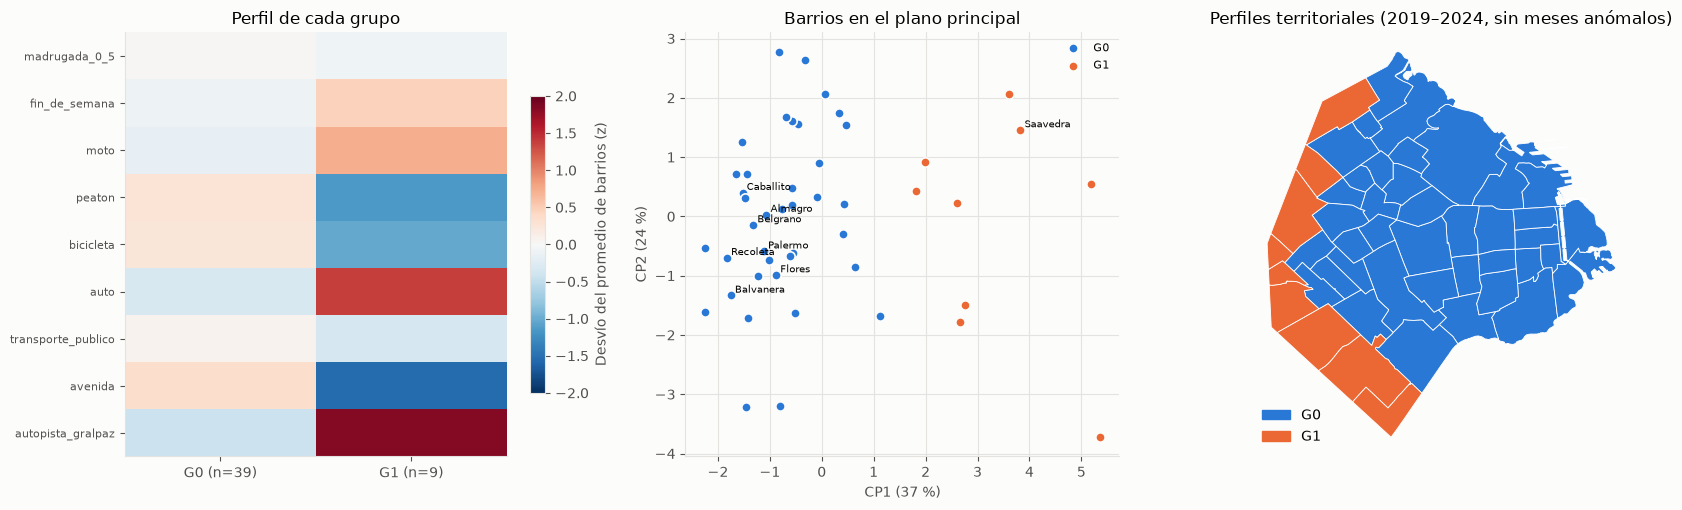

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})
im = axes[0].imshow(zc.T.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto"); axes[0].grid(False)
axes[0].set_yticks(range(len(ATTR_R)), [c.replace("pct_", "") for c in ATTR_R], fontsize=8); axes[0].set_xticks(range(k), [f"G{g} (n={int(prof.loc[g,'n_barrios'])})" for g in range(k)])
fig.colorbar(im, ax=axes[0], shrink=.7, label="Desvío del promedio de barrios (z)"); axes[0].set_title("Perfil de cada grupo")
pc = PCA(2, random_state=SEED).fit(Zs); xy = pc.transform(Zs)
for g in range(k):
    axes[1].scatter(xy[LAB == g, 0], xy[LAB == g, 1], s=45, color=CAT[g], edgecolor=SURFACE, lw=1.2, label=f"G{g}")
for i, b in enumerate(A.index):
    if A.loc[b, "hechos"] > A["hechos"].quantile(.85): axes[1].annotate(b, xy[i], fontsize=7, xytext=(3, 2), textcoords="offset points")
axes[1].set_xlabel(f"CP1 ({pc.explained_variance_ratio_[0]*100:.0f} %)"); axes[1].set_ylabel(f"CP2 ({pc.explained_variance_ratio_[1]*100:.0f} %)")
axes[1].set_title("Barrios en el plano principal"); axes[1].legend(frameon=False, fontsize=8)
g = gpd.read_file(ROOT / "data" / "raw" / "limites" / "barrios.geojson").rename(columns={"nombre": "barrio"}).merge(A[["grupo"]].reset_index(), on="barrio")
for gg in range(k):
    g[g["grupo"] == gg].plot(ax=axes[2], color=CAT[gg], edgecolor="white", lw=.6, label=f"G{gg}")
axes[2].set_axis_off(); axes[2].set_title("Perfiles territoriales (2019–2024, sin meses anómalos)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CAT[gg]) for gg in range(k)]
axes[2].legend(handles, [f"G{gg}" for gg in range(k)], frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "perfiles_mapa.png", dpi=150); plt.show()

**Lectura (5): dos perfiles, *silhouette* 0,33, separación razonable.**

| Perfil | Barrios | Rasgos (promedio de barrios) |
|---|---|---|
| **G1: borde (Gral. Paz/autopistas)**, 9 barrios | Liniers, Mataderos, Saavedra, Versalles, Villa Devoto, Villa Lugano, Villa Pueyrredón, Villa Real, Villa Riachuelo | **35 % de los hechos en autopista o General Paz** (frente a 2 %), 35 % en avenidas (frente a 63 %), **más auto** (19 % frente a 12 %) y moto (49 % frente a 44 %), **menos peatón** (12 % frente a 18 %) y bicicleta (8 % frente a 13 %) |
| **G0: interior**, 39 barrios | Todos los demás | Siniestralidad en avenidas y calles, con más peatones, ciclistas y transporte público |

El volumen es similar (826 frente a 929 hechos por barrio en la ventana) y la proporción KSI es prácticamente igual (5,0 % frente a 4,9 %, solo descriptiva). Es un perfil **por el tipo de vía y los actores involucrados**: los barrios del borde oeste y sur concentran hechos de vías rápidas y de vehículos.

**Limitación.** La partición refleja en gran medida una condición geográfica estructural, la presencia de la General Paz y las autopistas. Es útil para orientar el **tipo** de prevención (vías rápidas frente a usuarios vulnerables en avenidas), no para predecir el volumen.

## 5b. Segundo nivel de la tipología: la alternativa k = 3 (también elegible)

La regla de selección elige k = 2. La solución K-Means con k = 3 también es elegible (ARI ≥ 0,60 y grupos de al menos 3 barrios), aunque con menor *silhouette*. Se presenta como **refinamiento descriptivo**, no como selección. Se verifica si **anida** a la solución elegida, es decir, si conserva el mismo grupo de borde.

También se informa la estructura que queda **sin la familia "tipo de vía"**, que es la que domina la partición de k = 2.

> **Qué hace la celda siguiente.** Examina la alternativa de tres grupos, verifica que conserve el grupo de borde y describe en qué se diferencian las dos mitades del interior.

In [9]:
LAB3 = SOL[("R", "standard", "kmeans", 3)]
ct = pd.crosstab(pd.Series(LAB, index=A.index, name="k2"), pd.Series(LAB3, index=A.index, name="k3"))
borde = int(pd.Series(LAB).value_counts().idxmin())
anida = bool(((ct > 0).sum(axis=0) == 1).all())
# Etiquetas legibles: el grupo de borde y, dentro del interior, el de mayor volumen ("central") y el de menor ("residencial")
A["k3"] = LAB3
g3 = A.groupby("k3")
borde3 = int(ct.loc[borde].idxmax())
inter = [g for g in range(3) if g != borde3]
central = max(inter, key=lambda g: g3["hechos"].mean()[g]); resid = [g for g in inter if g != central][0]
names3 = {borde3: "Borde (Gral. Paz/autopistas)", central: "Interior central-denso", resid: "Interior residencial"}
prof3 = g3[ATTR_R + ["hechos", "log_densidad_km2_anio", "pct_ksi", "frec_top10"]].mean().rename(index=names3)
prof3.insert(0, "n_barrios", g3.size().rename(index=names3))
prof3["barrios"] = g3.apply(lambda d: ", ".join(sorted(d.index))).rename(index=names3)
r3 = res[(res["conjunto"] == "R") & (res["escalado"] == "standard") & (res["metodo"] == "kmeans") & (res["k"] == 3)].iloc[0]
Zn = Z_of([c for c in ATTR_R if c not in P.ATTR_VIA])
sinvia = {kk: round(float(silhouette_score(Zn, KMeans(kk, n_init=50, random_state=SEED).fit_predict(Zn))), 3) for kk in range(2, 6)}
M["k3"] = {"anida_en_k2": anida, "silhouette": round(float(r3["silhouette"]), 3), "ari_bootstrap_media": round(float(r3["ari_bootstrap_media"]), 3),
           "perfiles": {n: {"n": int(r["n_barrios"]), **{c: round(float(r[c]), 3) for c in ATTR_R + ["hechos", "pct_ksi", "frec_top10"]}} for n, r in prof3.iterrows()},
           "silhouette_sin_via_k2_a_k5": sinvia}
prof3.to_csv(TAB / "perfiles_k3.csv"); A[["grupo", "k3"]].assign(perfil_k3=A["k3"].map(names3)).to_csv(TAB / "asignacion_barrios.csv")
pct3 = prof3[[c for c in ATTR_R] + ["pct_ksi", "frec_top10"]].mul(100).round(1)
print("¿Anida en k = 2?", anida, "| silhouette sin la familia vía, k=2..5:", sinvia)
display(pd.concat([prof3[["n_barrios", "hechos"]].round(0), pct3], axis=1)); prof3["barrios"]

¿Anida en k = 2? True | silhouette sin la familia vía, k=2..5: {2: 0.215, 3: 0.226, 4: 0.208, 5: 0.197}


,n_barrios,hechos,pct_madrugada_0_5,pct_fin_de_semana,pct_moto,pct_peaton,pct_bicicleta,pct_auto,pct_transporte_publico,pct_avenida,pct_autopista_gralpaz,pct_ksi,frec_top10
k3,,,,,,,,,,,,,
Interior residencial,22,734.0,6.9,19.9,46.8,16.3,14.8,11.3,5.5,61.4,2.0,4.7,15.5
Borde (Gral. Paz/autopistas),9,826.0,7.2,21.8,49.0,11.7,8.3,19.2,6.0,34.5,35.3,5.0,16.6
Interior central-denso,17,1182.0,8.0,20.9,40.8,19.8,11.3,13.5,8.5,65.6,2.0,5.3,29.9


k3
Interior residencial            Agronomia, Almagro, Belgrano, Boedo, Caballito...
Borde (Gral. Paz/autopistas)    Liniers, Mataderos, Saavedra, Versalles, Villa...
Interior central-denso          Balvanera, Barracas, Constitucion, Flores, Flo...
Name: barrios, dtype: str

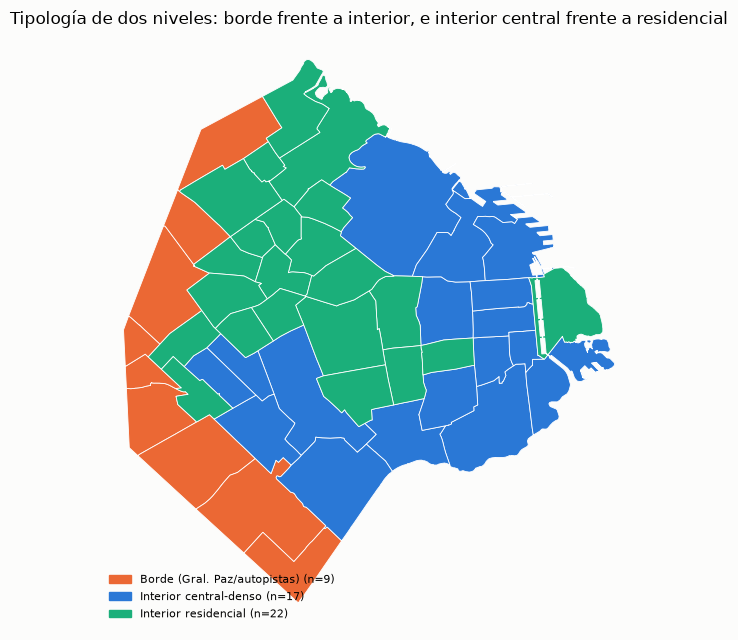

In [10]:
fig, ax = plt.subplots(figsize=(7, 6.5))
cols3 = {names3[borde3]: CAT[1], names3[central]: CAT[0], names3[resid]: CAT[2]}
g = gpd.read_file(ROOT / "data" / "raw" / "limites" / "barrios.geojson").rename(columns={"nombre": "barrio"}).merge(A[["k3"]].reset_index(), on="barrio")
g["perfil"] = g["k3"].map(names3)
for n, c in cols3.items():
    g[g["perfil"] == n].plot(ax=ax, color=c, edgecolor="white", lw=.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cols3.values()], [f"{n} (n={int(prof3.loc[n, 'n_barrios'])})" for n in cols3], frameon=False, loc="lower left", fontsize=8)
ax.set_axis_off(); ax.set_title("Tipología de dos niveles: borde frente a interior, e interior central frente a residencial")
fig.tight_layout(); fig.savefig(FIG / "tipologia_k3.png", dpi=150); plt.show()

**Lectura (5b).** La solución k = 3 **anida** en la elegida: conserva el mismo grupo de borde y divide el interior en dos.
- **Interior central-denso** (17 barrios, de mayor volumen, entre ellos Balvanera, Constitución, Monserrat, Palermo y Recoleta): más peatones (20 %) y transporte público (8,5 %), y menos moto.
- **Interior residencial** (22 barrios): más moto (47 %) y bicicleta (15 %), y menor volumen.

Este segundo nivel es **estable** (ARI 0,70), pero su **separación es débil** (*silhouette* 0,195 < 0,25). Lo mismo vale para la estructura sin la familia de vía (*silhouette* ≤ 0,23 entre k = 2 y k = 5). Por eso se presenta como una **tipología descriptiva de dos niveles**: un primer nivel robusto (borde frente a interior) y un segundo nivel orientativo (central frente a residencial).

## 6. Registro

> **Qué hace la celda siguiente.** Guarda las cifras del notebook en `clustering_metrics.json`. La asignación de cada barrio (`asignacion_barrios.csv`) ya quedó guardada en las secciones 5 y 5b. Ambos archivos los usan el notebook 06, la web pública y el informe [docs/clustering_report.md](../docs/clustering_report.md).

In [11]:
(TAB / "clustering_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado:", (TAB / "clustering_metrics.json").relative_to(ROOT))

Guardado: reports\tables\05_clustering\clustering_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Respuesta a la pregunta.** Sí: los barrios se dividen con solidez en un perfil de **borde** (vías rápidas, autos y motos) y otro de **interior** (avenidas y calles, más peatones, ciclistas y transporte público). La subdivisión del interior es orientativa.
- **Para qué sirve.** Para elegir el tipo de prevención según el perfil: vías rápidas y conductores en el borde; usuarios vulnerables en avenidas en el interior central; motociclistas y ciclistas en el interior residencial.
- **Límites.** Los perfiles describen la composición de los hechos registrados, no el riesgo por persona ni por viaje (no hay datos de exposición). El perfil de borde refleja en gran parte una condición geográfica: la presencia de la General Paz y las autopistas.
- **Siguiente paso.** El notebook 06 usa estos perfiles para revisar si la priorización por conteo deja barrios o perfiles subrepresentados.